# DL PR 6 - Opening the Transformer
**Red & White Skill Education - Deep Learning**

In this notebook I use small pretrained Hugging Face models (no training) and open them up to see how attention, the encoder, the decoder and inference really work.

| Model ID | Family | Used for |
| --- | --- | --- |
| `distilbert-base-uncased-finetuned-sst-2-english` | Encoder-only | sentiment, attention inspection |
| `distilbert-base-uncased` | Encoder-only | fill-mask |
| `gpt2` | Decoder-only | causal attention, generation |
| `t5-small` | Encoder-decoder | cross-attention, translation, summary |

In [1]:
# Install (run once, then comment out)
# !pip install transformers torch datasets matplotlib seaborn numpy pandas

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import (pipeline, AutoTokenizer, AutoModel,
                          AutoModelForSequenceClassification,
                          AutoModelForCausalLM, T5ForConditionalGeneration)

warnings.filterwarnings("ignore")

# seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

os.makedirs("plots", exist_ok=True)   # all figures are saved here

SENT_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
print("Setup done")

C:\Users\MAITRAK\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1021 17:35:35.922000 1916 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Setup done


# Task 1: Introduction, History, Pipelines & Tokenizer
**Objective:** Run a first pipeline, learn the history of Transformers, and see how text becomes tokens.
**Expected output:** Sentiment results, history table, tokenizer output, padded batch, model config table.

### 1.1 First pipeline

In [3]:
clf = pipeline("sentiment-analysis", model=SENT_MODEL)

sentences = [
    "I really loved this movie, it was fantastic!",          # positive
    "This was the worst film I have ever seen.",             # negative
    "The food was okay but the service was terrible.",       # mixed
    "The movie was not bad at all.",                         # tricky: negation
    "I can't say that I didn't enjoy it.",                   # tricky: double negation
]

for s in sentences:
    r = clf(s)[0]
    print(f"{r['label']:9s} {r['score']:.3f}  |  {s}")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 743.68it/s]


POSITIVE  1.000  |  I really loved this movie, it was fantastic!
NEGATIVE  1.000  |  This was the worst film I have ever seen.
NEGATIVE  0.992  |  The food was okay but the service was terrible.
POSITIVE  0.998  |  The movie was not bad at all.
NEGATIVE  0.999  |  I can't say that I didn't enjoy it.


One `pipeline` call hides **three steps**: (1) tokenisation (text to ids), (2) the model forward pass (ids to logits), (3) post-processing (softmax and picking the label).

### 1.2 Introduction & History

| Year | Model / Paper | Why it mattered |
| --- | --- | --- |
| 2014-15 | Seq2seq with attention (Bahdanau, Luong) | Decoder could look back at all encoder states instead of one fixed vector |
| 2017 | "Attention Is All You Need" (Vaswani et al.) | Removed RNNs completely, only attention, trains in parallel |
| 2018 | BERT and GPT | Pretrain on huge text, then reuse for many tasks |
| 2019 | GPT-2, T5, DistilBERT | Bigger generators, text-to-text framework, smaller faster models |
| 2020+ | GPT-3 and other LLMs, Vision Transformer (ViT) | Scaling up; Transformers also used for images |

**What problem with RNN / LSTM did the Transformer solve?** RNNs read words one by one, so they cannot be parallelised and training is slow. They also have short memory: information from early words fades over long sentences. The Transformer lets every token look at every other token directly, and all tokens are processed at the same time.

### 1.3 Impact & Disadvantages

**Impact (tasks transformed by Transformers)**
- Machine translation
- Web search and question answering
- Chat assistants
- Code completion
- Image models (ViT, image generation)
- Protein structure prediction (AlphaFold)

**Disadvantages**
- Attention cost grows with the square of sequence length
- Fixed context window
- Large compute and memory needs
- Needs huge amounts of data
- Hallucination in generative models
- Opaque behaviour (hard to explain)

I will measure two of these myself in Task 6 (cost vs length, and hallucination).

### 1.4 Tokenizer in action

In [4]:
tok = AutoTokenizer.from_pretrained(SENT_MODEL)

text = "Transformers are surprisingly easy to understand."
print("tokens        :", tok.tokenize(text))
enc = tok(text)
print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])

# a rare / long word gets split into sub-word pieces
print()
print(tok.tokenize("electroencephalography"))
print(tok.tokenize("unbelievably"))

tokens        : ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
input_ids     : [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]

['electro', '##ence', '##pha', '##log', '##raphy']
['un', '##bel', '##ie', '##va', '##bly']


`[CLS]` is added at the start (its output is used for classification) and `[SEP]` marks the end of a sentence. Sub-words are used instead of whole words because a fixed vocabulary can then still handle rare or new words by breaking them into known pieces.

### 1.5 Batching and padding

In [5]:
batch = tok(["I love it.", "This movie was long but I enjoyed every single minute of it."],
            padding=True, return_tensors="pt")

print("input_ids:")
print(batch["input_ids"])
print("attention_mask:")
print(batch["attention_mask"])

input_ids:
tensor([[ 101, 1045, 2293, 2009, 1012,  102,    0,    0,    0,    0,    0,    0,
            0,    0,    0],
        [ 101, 2023, 3185, 2001, 2146, 2021, 1045, 5632, 2296, 2309, 3371, 1997,
         2009, 1012,  102]])
attention_mask:
tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


The `attention_mask` is 1 for real tokens and 0 for padding, so the model ignores padding. I show the effect in Task 4.8.

### 1.6 Model anatomy at a glance

In [6]:
model = AutoModelForSequenceClassification.from_pretrained(SENT_MODEL)
model.eval()

cfg = model.config
total_params = sum(p.numel() for p in model.parameters())

summary = pd.DataFrame({
    "Item": ["Layers", "Attention heads", "Hidden size", "Vocabulary size",
             "Max position embeddings", "Total parameters"],
    "Value": [cfg.n_layers, cfg.n_heads, cfg.dim, cfg.vocab_size,
              cfg.max_position_embeddings, total_params],
})
print(summary)

print()
print("First 15 parameter names:")
for i, (name, p) in enumerate(model.named_parameters()):
    if i == 15:
        break
    print(name, tuple(p.shape))

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 707.24it/s]

                      Item     Value
0                   Layers         6
1          Attention heads        12
2              Hidden size       768
3          Vocabulary size     30522
4  Max position embeddings       512
5         Total parameters  66955010

First 15 parameter names:
distilbert.embeddings.word_embeddings.weight (30522, 768)
distilbert.embeddings.position_embeddings.weight (512, 768)
distilbert.embeddings.LayerNorm.weight (768,)
distilbert.embeddings.LayerNorm.bias (768,)
distilbert.transformer.layer.0.attention.q_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.q_lin.bias (768,)
distilbert.transformer.layer.0.attention.k_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.k_lin.bias (768,)
distilbert.transformer.layer.0.attention.v_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.v_lin.bias (768,)
distilbert.transformer.layer.0.attention.out_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.out_lin.bias (768,)
distil

I will explain each number in Tasks 2-4: heads and hidden size in Task 3, max positions in 3.6, layers in Task 4.

# Task 2: Self-Attention & Scaled Dot-Product Attention
**Objective:** Build self-attention from scratch in NumPy and verify it against a real DistilBERT layer.
**Expected output:** Attention heatmap, scaling experiment, Luong attention, order-blind demo, verification with `np.allclose`.

### 2.1 Self-attention idea
Every token is turned into three vectors: a **Query** (what am I looking for?), a **Key** (what do I offer?) and a **Value** (what do I pass on?). The new representation of a token is a weighted average of all Value vectors. The weights come from how well its Query matches every Key. The whole sequence is processed in parallel, unlike an RNN.

### 2.2 Scaled dot-product attention from scratch

X      : (4, 8)
Q,K,V  : (4, 8) (4, 8) (4, 8)
scores : (4, 4)
weights: (4, 4)
output : (4, 8)

row sums: [1. 1. 1. 1.]
all rows sum to 1: True


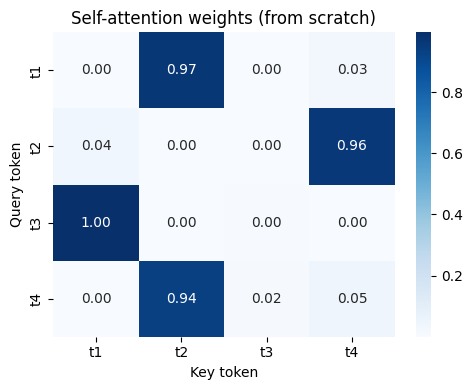

In [7]:
def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)   # subtract max for stability
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)


def self_attention(X, Wq, Wk, Wv, mask=None, verbose=False):
    Q = X @ Wq
    K = X @ Wk
    V = X @ Wv
    d_k = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)
    if mask is not None:
        scores = scores + mask          # used later for causal mask
    weights = softmax(scores, axis=-1)
    output = weights @ V
    if verbose:
        print("X      :", X.shape)
        print("Q,K,V  :", Q.shape, K.shape, V.shape)
        print("scores :", scores.shape)
        print("weights:", weights.shape)
        print("output :", output.shape)
    return output, weights


np.random.seed(42)
X = np.random.randn(4, 8)          # 4 tokens, d_model = 8
Wq = np.random.randn(8, 8)
Wk = np.random.randn(8, 8)
Wv = np.random.randn(8, 8)

out, w = self_attention(X, Wq, Wk, Wv, verbose=True)
print()
print("row sums:", w.sum(axis=1))
print("all rows sum to 1:", np.allclose(w.sum(axis=1), 1))

labels = ["t1", "t2", "t3", "t4"]
plt.figure(figsize=(5, 4))
sns.heatmap(w, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Self-attention weights (from scratch)")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/attention_scratch.png", dpi=120)
plt.show()

### 2.3 Why divide by sqrt(d_k)?

In [8]:
def entropy(p):
    return -(p * np.log(p + 1e-12)).sum(axis=-1)


np.random.seed(42)
rows = []
for d_k in [4, 256]:
    Q = np.random.randn(10, d_k)
    K = np.random.randn(10, d_k)
    for scaled in [False, True]:
        scores = Q @ K.T
        if scaled:
            scores = scores / np.sqrt(d_k)
        p = softmax(scores)
        rows.append({"d_k": d_k, "scaled": scaled,
                     "avg max prob": round(p.max(axis=1).mean(), 3),
                     "avg entropy": round(entropy(p).mean(), 3)})

print(pd.DataFrame(rows))
print("max possible entropy for 10 keys =", round(np.log(10), 3))

   d_k  scaled  avg max prob  avg entropy
0    4   False         0.485        1.465
1    4    True         0.286        1.989
2  256   False         0.864        0.333
3  256    True         0.275        1.982
max possible entropy for 10 keys = 2.303


Dot products grow in size as `d_k` grows (variance is about `d_k`). Large scores push softmax into a **saturated** region where one weight is almost 1 and the others almost 0 (see `d_k = 256` without scaling: max prob near 1, entropy near 0). In that region the gradients almost vanish. Dividing by `sqrt(d_k)` keeps the variance near 1, so softmax stays smooth.

### 2.4 Self-attention vs Luong attention

In [9]:
np.random.seed(42)
enc_states = np.random.randn(5, 8)    # 5 encoder hidden states
dec_state = np.random.randn(8)        # 1 decoder hidden state

scores = enc_states @ dec_state       # (5,)
weights = softmax(scores)
context = weights @ enc_states        # (8,)

print("Luong weights:", np.round(weights, 3))
print("sum:", weights.sum())
print("context shape:", context.shape)

Luong weights: [0.048 0.101 0.001 0.616 0.234]
sum: 0.9999999999999999
context shape: (8,)


| Point | Luong (dot) attention | Self-attention |
| --- | --- | --- |
| Where Q, K, V come from | Query = decoder state; Keys/Values = encoder states | All three come from the same sequence (X @ Wq, Wk, Wv) |
| What is attended over | Decoder state looks at encoder states | Every token looks at every token |
| Needs an RNN? | Yes (works on RNN hidden states) | No |
| Parallelism | Limited (RNN is sequential) | Fully parallel |
| Where in the architecture | Between decoder and encoder of an RNN seq2seq | Inside every Transformer layer |

### 2.5 Attention is order-blind

In [10]:
perm = np.array([2, 0, 3, 1])        # fixed permutation

out_perm, _ = self_attention(X[perm], Wq, Wk, Wv)
print("Output of shuffled input = shuffled output of original:",
      np.allclose(out_perm, out[perm]))

Output of shuffled input = shuffled output of original: True


Shuffling the tokens only shuffles the output rows. Self-attention has **no notion of position**, so "dog bites man" and "man bites dog" would look the same. That is why Task 3 adds positional encoding.

### 2.6 Verify against a real model (DistilBERT, layer 0, head 0)

In [11]:
bert_model = AutoModel.from_pretrained(SENT_MODEL, attn_implementation="eager")
bert_model.eval()

sentence = "The animal did not cross the street because it was too tired."
enc = tok(sentence, return_tensors="pt")

with torch.no_grad():
    out_real = bert_model(**enc, output_hidden_states=True, output_attentions=True)

# my own calculation
att_layer = bert_model.transformer.layer[0].attention
x = out_real.hidden_states[0][0]           # (tokens, 768) input of layer 0
T = x.shape[0]

with torch.no_grad():
    q = att_layer.q_lin(x).view(T, 12, 64).transpose(0, 1)   # (12, T, 64)
    k = att_layer.k_lin(x).view(T, 12, 64).transpose(0, 1)
    scores = q @ k.transpose(1, 2) / np.sqrt(64)
    my_attn = torch.softmax(scores, dim=-1)[0].numpy()        # head 0

real_attn = out_real.attentions[0][0, 0].numpy()

print("allclose:", np.allclose(my_attn, real_attn, atol=1e-4))
print("max abs difference:", np.abs(my_attn - real_attn).max())

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 680.62it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


allclose: True
max abs difference: 0.0


A match means my NumPy-style understanding (project with Q and K, split into heads, divide by sqrt(64), softmax) is exactly what the real model does in layer 0, head 0. No padding was used here, so no padding mask was needed.

# Task 3: Multi-Head Attention, Positional Encoding & Layer Normalization
**Objective:** See real attention heads, build positional encoding and LayerNorm from scratch.
**Expected output:** Head heatmaps, entropy bars, positional encoding plots, LayerNorm checks.

### 3.1 Multi-head attention
One attention pattern is not enough because a token may need to look at different things at once (previous word, the subject, punctuation). With `h` heads, `d_model` is split into `h` smaller parts (DistilBERT: 768 = 12 x 64). Each head has its own Q, K, V projections and its own attention pattern. The heads are then concatenated and mixed by an output projection. The total computation is about the same as one big head.

### 3.2 Extract and plot real attention heads

number of layers: 6
layer 0: (1, 12, 15, 15)
layer 1: (1, 12, 15, 15)
layer 2: (1, 12, 15, 15)
layer 3: (1, 12, 15, 15)
layer 4: (1, 12, 15, 15)
layer 5: (1, 12, 15, 15)


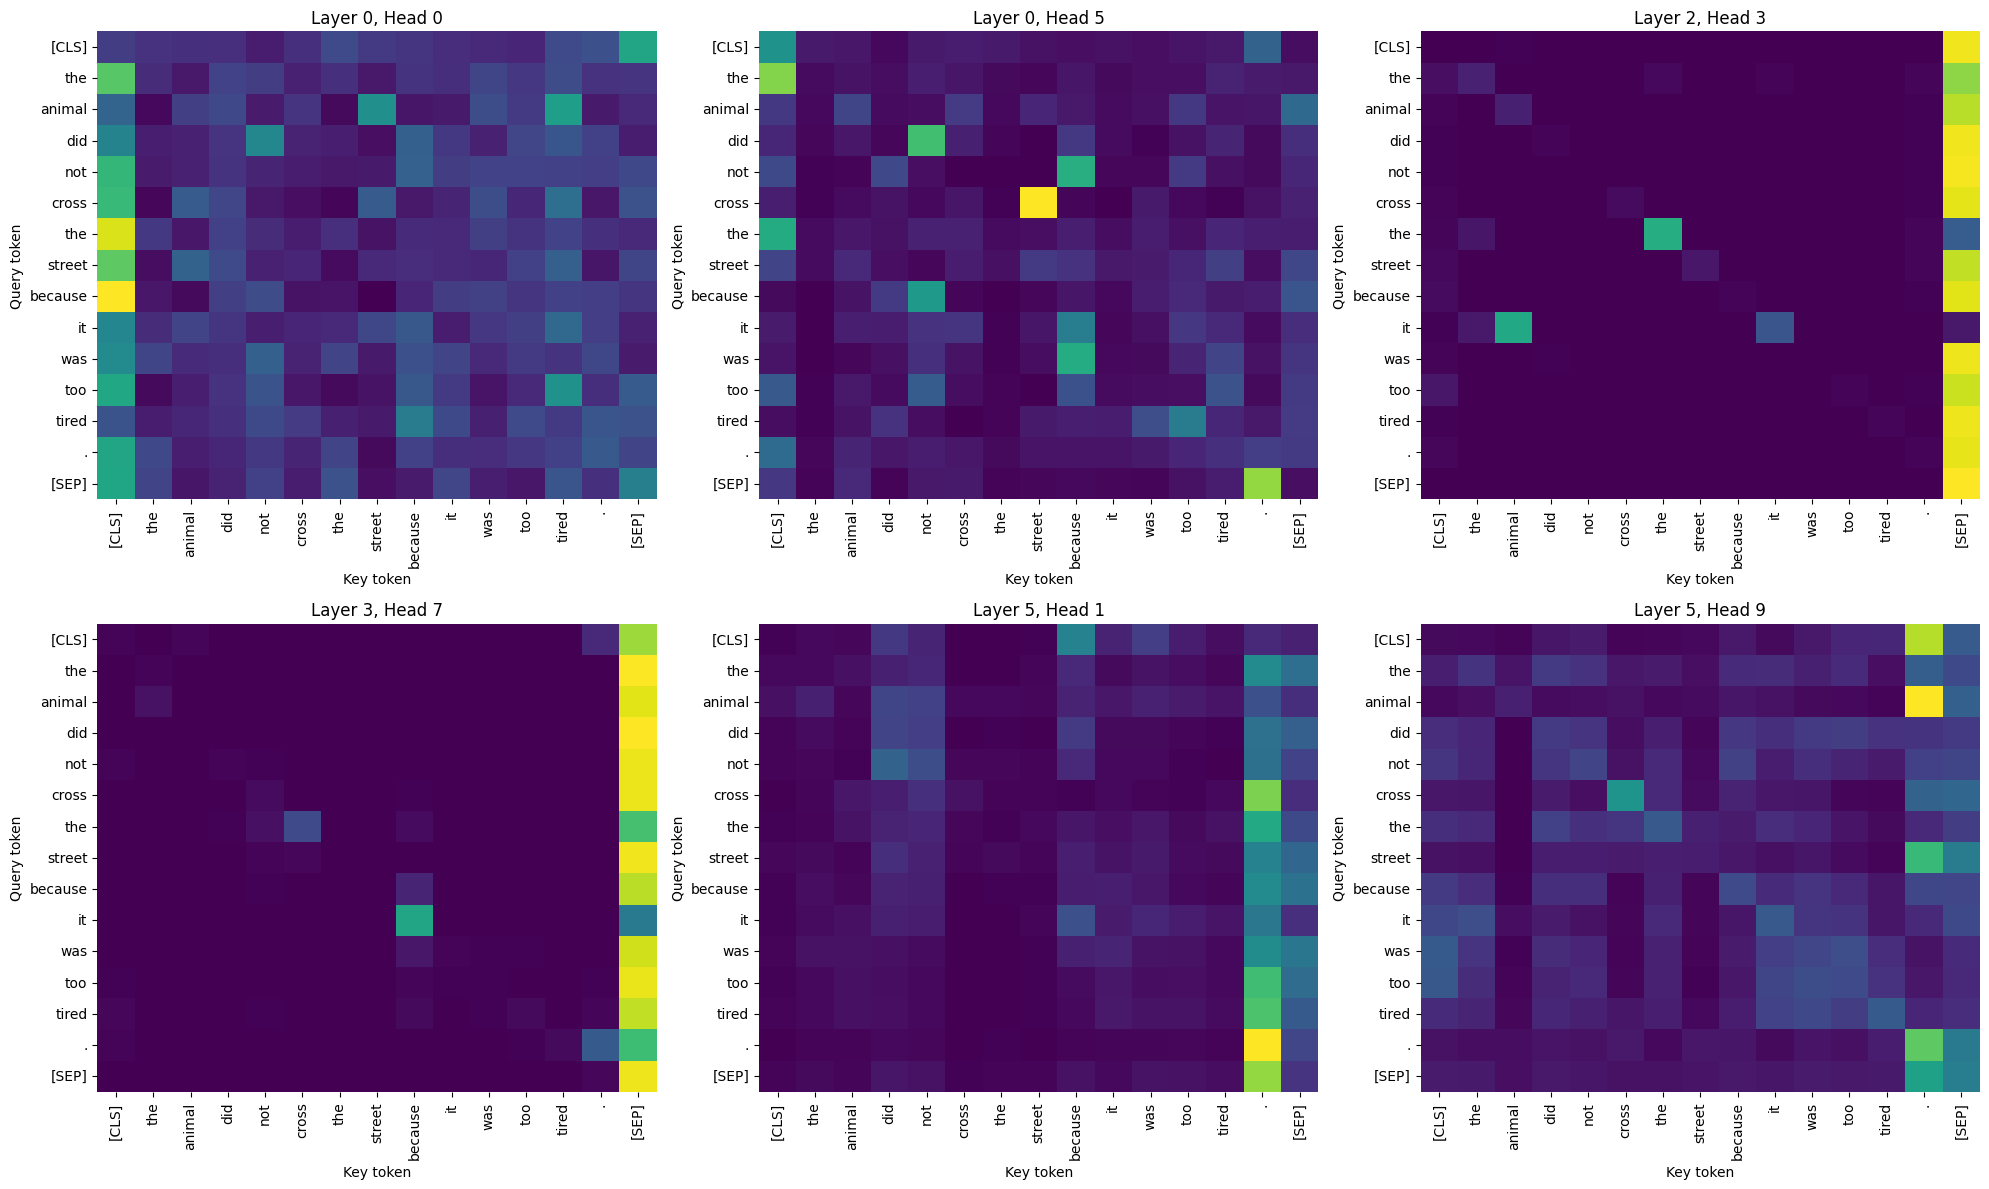

In [12]:
attentions = out_real.attentions            # tuple of 6 tensors
print("number of layers:", len(attentions))
for i, a in enumerate(attentions):
    print(f"layer {i}:", tuple(a.shape))

tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])

heads = [(0, 0), (0, 5), (2, 3), (3, 7), (5, 1), (5, 9)]   # (layer, head)
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, (l, h) in zip(axes.flatten(), heads):
    a = attentions[l][0, h].numpy()
    sns.heatmap(a, xticklabels=tokens, yticklabels=tokens, cmap="viridis", ax=ax, cbar=False)
    ax.set_title(f"Layer {l}, Head {h}")
    ax.set_xlabel("Key token")
    ax.set_ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/attention_heads.png", dpi=100)
plt.show()

**Behaviours I see** (look at your own plot and edit this):
- Some heads put most weight on `[CLS]` / `[SEP]` (a bright column at the first or last token).
- Some heads look mainly at the previous or next token (a bright line next to the diagonal).
- Check whether any head links `it` with `animal` or `street`.

### 3.3 Head diversity (attention entropy)

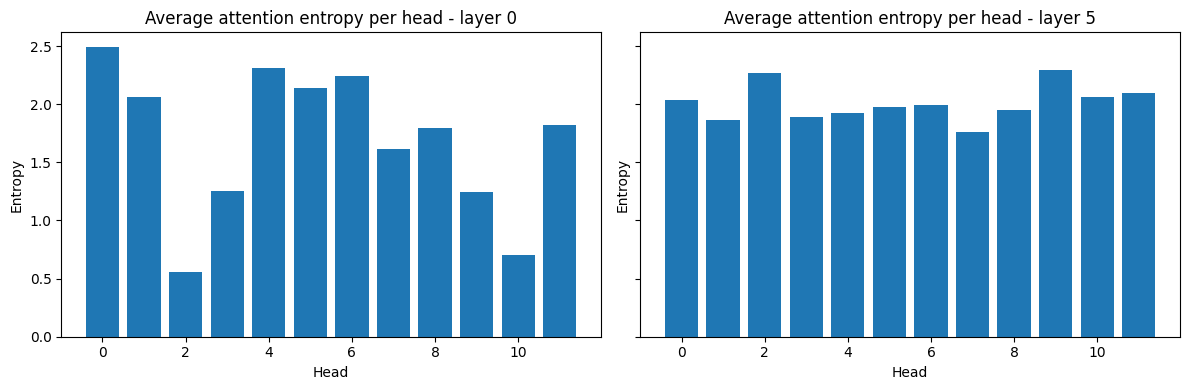

In [13]:
def head_entropy(layer):
    a = attentions[layer][0].numpy()                      # (12, T, T)
    ent = -(a * np.log(a + 1e-12)).sum(axis=-1)           # (12, T)
    return ent.mean(axis=-1)                              # (12,)


fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, layer in zip(axes, [0, 5]):
    ax.bar(range(12), head_entropy(layer))
    ax.set_title(f"Average attention entropy per head - layer {layer}")
    ax.set_xlabel("Head")
    ax.set_ylabel("Entropy")
plt.tight_layout()
plt.show()

(Edit after looking at the plot) In my run, the heads of layer 0 and the last layer differ in how spread out their attention is, but with one sentence I only make a modest claim.

### 3.4 Sinusoidal positional encoding from scratch

PE shape: (50, 128)


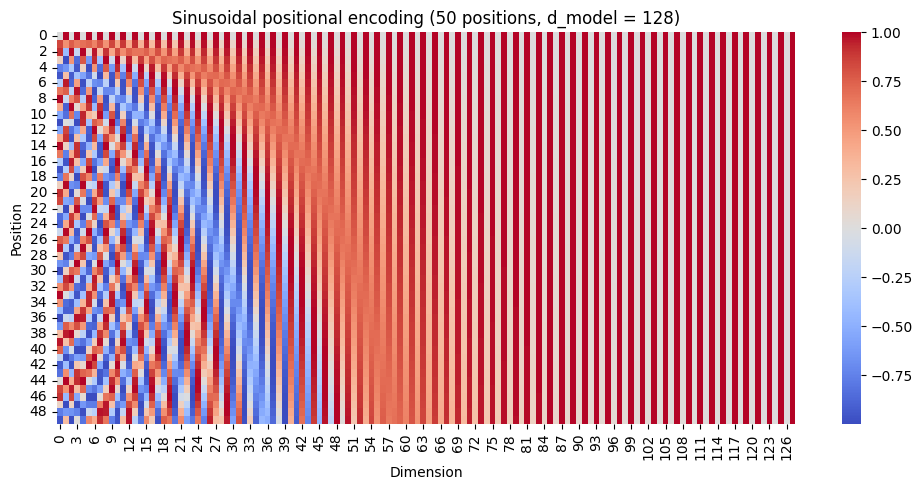

In [14]:
def positional_encoding(n_pos, d_model):
    pe = np.zeros((n_pos, d_model))
    pos = np.arange(n_pos)[:, None]               # (n_pos, 1)
    two_i = np.arange(0, d_model, 2)[None, :]     # 0, 2, 4, ...
    angle = pos / (10000 ** (two_i / d_model))
    pe[:, 0::2] = np.sin(angle)
    pe[:, 1::2] = np.cos(angle)
    return pe


pe = positional_encoding(50, 128)
print("PE shape:", pe.shape)

plt.figure(figsize=(10, 5))
sns.heatmap(pe, cmap="coolwarm")
plt.title("Sinusoidal positional encoding (50 positions, d_model = 128)")
plt.xlabel("Dimension")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig("plots/positional_encoding.png", dpi=120)
plt.show()

Sines and cosines with different frequencies give every position its own unique pattern, and the shift between two positions is a simple pattern the model can learn (relative offsets are easy to learn).

### 3.5 Position makes identical words different

In [15]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


np.random.seed(42)
word = np.random.randn(128)

at_3 = word + pe[3]
at_20 = word + pe[20]

print("cosine without PE:", cosine(word, word))
print("cosine with PE (pos 3 vs pos 20):", round(cosine(at_3, at_20), 3))

cosine without PE: 1.0000000000000002
cosine with PE (pos 3 vs pos 20): 0.859


Without PE the same word has the same vector everywhere (similarity 1.0), so attention cannot tell positions apart (Task 2.5). After adding PE the two copies are different, so the attention output now depends on order and the order-blindness is removed.

### 3.6 Learned positional embeddings in DistilBERT

position embedding shape: (512, 768)


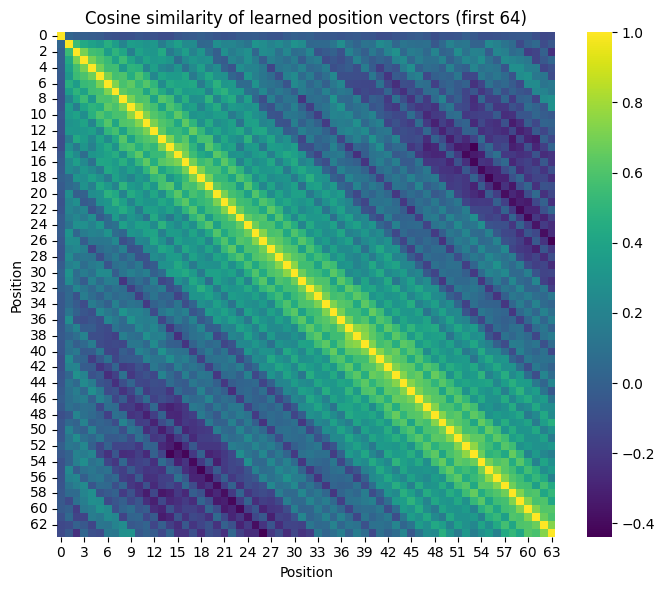

In [16]:
pos_w = model.distilbert.embeddings.position_embeddings.weight.detach().numpy()
print("position embedding shape:", pos_w.shape)

first = pos_w[:64]
unit = first / np.linalg.norm(first, axis=1, keepdims=True)
sim = unit @ unit.T

plt.figure(figsize=(7, 6))
sns.heatmap(sim, cmap="viridis")
plt.title("Cosine similarity of learned position vectors (first 64)")
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout()
plt.show()

BERT-style models **learn** their position vectors instead of using sinusoids. There are only 512 of them, which is the origin of the 512-token context limit. (T5 uses relative position biases instead, seen in Task 5.)

### 3.7 Layer normalization from scratch

In [17]:
def layer_norm(x, gamma=1.0, beta=0.0, eps=1e-5):
    mean = x.mean(axis=-1, keepdims=True)      # over the FEATURE dimension
    var = x.var(axis=-1, keepdims=True)
    return gamma * (x - mean) / np.sqrt(var + eps) + beta


np.random.seed(42)
M = np.random.randn(4, 8) * 3 + 5       # 4 tokens x 8 features

ln_out = layer_norm(M)
print("per-token mean:", np.round(ln_out.mean(axis=1), 4))
print("per-token std :", np.round(ln_out.std(axis=1), 4))

torch_ln = torch.nn.LayerNorm(8)        # gamma = 1, beta = 0 by default
torch_out = torch_ln(torch.tensor(M, dtype=torch.float32))
print("matches torch.nn.LayerNorm:",
      torch.allclose(torch.tensor(ln_out, dtype=torch.float32), torch_out, atol=1e-5))

per-token mean: [-0.  0. -0. -0.]
per-token std : [1. 1. 1. 1.]
matches torch.nn.LayerNorm: True


### 3.8 LayerNorm vs BatchNorm

In [18]:
# BatchNorm style: normalise each FEATURE across the 4 tokens
bn_out = (M - M.mean(axis=0)) / np.sqrt(M.var(axis=0) + 1e-5)

print("BatchNorm per-feature mean:", np.round(bn_out.mean(axis=0), 3))
print("BatchNorm per-token mean  :", np.round(bn_out.mean(axis=1), 3), "<- NOT zero")
print("BatchNorm per-token std   :", np.round(bn_out.std(axis=1), 3), "<- NOT one")

ln = model.distilbert.embeddings.LayerNorm
print()
print("DistilBERT embedding LayerNorm gamma:", tuple(ln.weight.shape))
print("DistilBERT embedding LayerNorm beta :", tuple(ln.bias.shape))

BatchNorm per-feature mean: [ 0.  0.  0.  0.  0.  0.  0. -0.]
BatchNorm per-token mean  : [ 0.652 -0.354 -0.191 -0.108] <- NOT zero
BatchNorm per-token std   : [1.044 0.867 0.994 0.756] <- NOT one

DistilBERT embedding LayerNorm gamma: (768,)
DistilBERT embedding LayerNorm beta : (768,)


| Point | LayerNorm | BatchNorm |
| --- | --- | --- |
| Normalised over | Features of one token | One feature across the batch |
| Depends on batch size? | No | Yes |
| Variable-length sequences / padding | Works fine (each token alone) | Padding pollutes the statistics |
| Used in | Transformers | CNNs (PR 2) |

Transformers use LayerNorm because sequences have different lengths with padding and batches can be small. **gamma** is a learned scale and **beta** is a learned shift (one value per feature, 768 each), so the model can undo the normalisation if it wants.

# Task 4: Transformer Encoder & Masked Self-Attention
**Objective:** Understand the encoder block, and the difference between bidirectional and causal attention.
**Expected output:** Module table, parameter chart, fill-mask results, bidirectional vs causal heatmaps, padding demo.

### 4.1 Encoder architecture
Input embeddings + positional information go through N stacked blocks. Each block is:
multi-head self-attention -> residual connection + LayerNorm -> feed-forward network (expand, non-linearity, project back) -> residual connection + LayerNorm.

DistilBERT has 6 such blocks, each with 12 heads and a feed-forward network. "Encoder" means every token can see every other token in **both directions**.

### 4.2 Print and read the real encoder

In [19]:
print(model.distilbert)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

| Part | Module name in DistilBERT |
| --- | --- |
| Token embedding | `embeddings.word_embeddings` |
| Position embedding | `embeddings.position_embeddings` |
| Embedding LayerNorm | `embeddings.LayerNorm` |
| Attention block | `transformer.layer[i].attention` with `q_lin`, `k_lin`, `v_lin`, `out_lin` |
| Feed-forward block | `transformer.layer[i].ffn` with `lin1`, `lin2`, activation (GELU) |
| Two LayerNorms per block | `sa_layer_norm` (after attention) and `output_layer_norm` (after feed-forward) |

The feed-forward network expands 768 -> 3072 and projects back 3072 -> 768.

### 4.3 Where do the parameters live?

                 group  parameters  share %
0           embeddings    23834112    35.60
1            attention    14174208    21.17
2         feed-forward    28334592    42.32
3          layer norms       19968     0.03
4  classification head      592130     0.88
total: 66955010 (same as before: True )


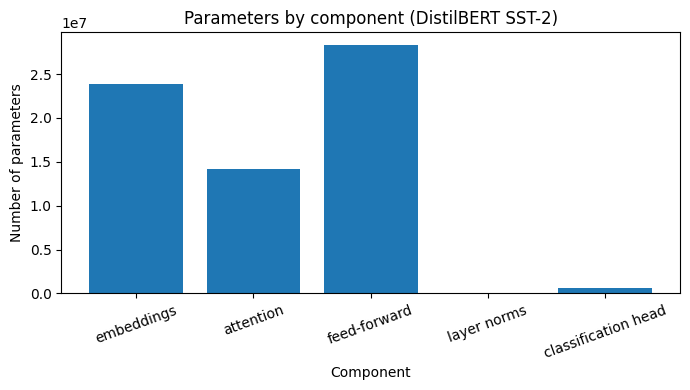

In [20]:
groups = {"embeddings": 0, "attention": 0, "feed-forward": 0, "layer norms": 0, "classification head": 0}

for name, p in model.named_parameters():
    n = p.numel()
    if "LayerNorm" in name or "layer_norm" in name:
        groups["layer norms"] += n
    elif "embeddings" in name:
        groups["embeddings"] += n
    elif "attention" in name:
        groups["attention"] += n
    elif "ffn" in name:
        groups["feed-forward"] += n
    else:
        groups["classification head"] += n

total = sum(groups.values())
param_df = pd.DataFrame({"group": list(groups.keys()),
                         "parameters": list(groups.values())})
param_df["share %"] = (param_df["parameters"] / total * 100).round(2)
print(param_df)
print("total:", total, "(same as before:", total == total_params, ")")

plt.figure(figsize=(7, 4))
plt.bar(param_df["group"], param_df["parameters"])
plt.title("Parameters by component (DistilBERT SST-2)")
plt.xlabel("Component")
plt.ylabel("Number of parameters")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("plots/parameter_distribution.png", dpi=120)
plt.show()

(Edit after looking at the numbers) The embeddings and the feed-forward layers hold most of the parameters, not the attention. This suggests that a lot of the model's "knowledge" is stored in the word embeddings and the feed-forward layers.

### 4.4 Use the encoder: fill-mask

In [21]:
fill = pipeline("fill-mask", model="distilbert-base-uncased")

mask_sentences = [
    "The capital of France is [MASK].",
    "I put the milk in the [MASK] to keep it cold.",
    "She opened the [MASK] and started reading the book.",
]

for s in mask_sentences:
    print(s)
    for r in fill(s, top_k=3):
        print(f"   {r['token_str']:12s} {r['score']:.3f}")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1012.74it/s]


The capital of France is [MASK].
   marseille    0.143
   nantes       0.090
   toulouse     0.088
I put the milk in the [MASK] to keep it cold.
   fridge       0.275
   refrigerator 0.254
   oven         0.109
She opened the [MASK] and started reading the book.
   door         0.209
   book         0.179
   drawer       0.064


The model uses words on **both sides** of `[MASK]` to guess it. This is the bidirectional behaviour of an encoder.

### 4.5 Bidirectional attention heatmap

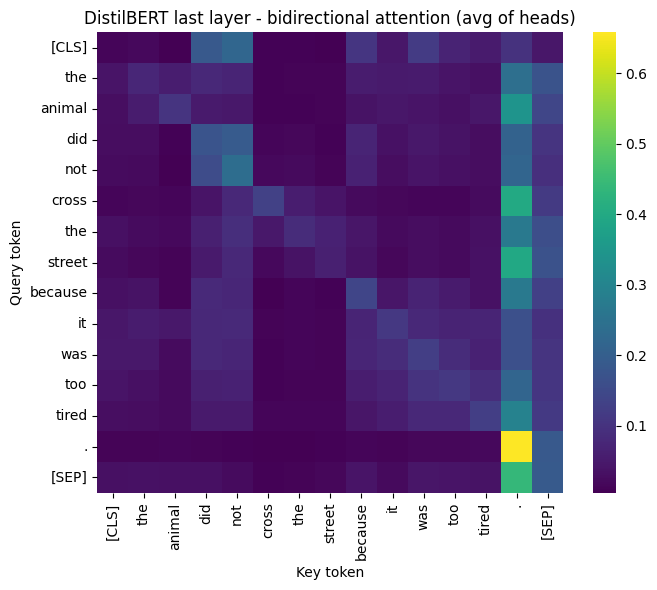

max weight above diagonal: 0.3990791
max weight below diagonal: 0.4407413


In [22]:
last = attentions[-1][0].numpy().mean(axis=0)     # average over 12 heads, (T, T)

plt.figure(figsize=(7, 6))
sns.heatmap(last, xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("DistilBERT last layer - bidirectional attention (avg of heads)")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/bidirectional_attention.png", dpi=120)
plt.show()

print("max weight above diagonal:", np.triu(last, k=1).max())
print("max weight below diagonal:", np.tril(last, k=-1).max())

There are non-zero weights above AND below the diagonal, so each token sees the future. This is NOT allowed in a language model that must predict the next word, because it would cheat by looking at the answer. That is why we need **masked self-attention**.

### 4.6 Masked (causal) self-attention from scratch

[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]
lower-triangular: True
rows sum to 1   : True


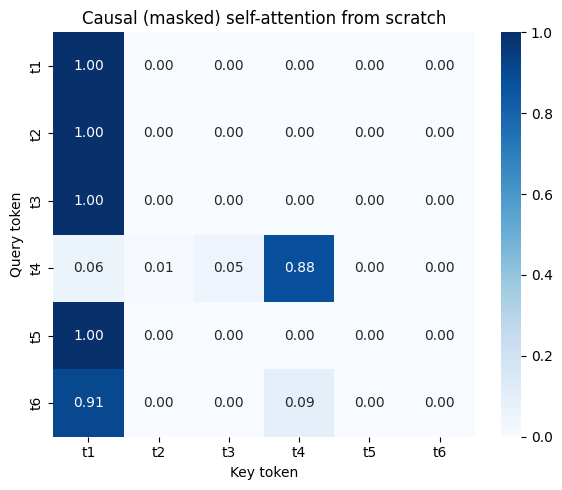

In [23]:
np.random.seed(42)
n = 6
X6 = np.random.randn(n, 8)
Wq6 = np.random.randn(8, 8)
Wk6 = np.random.randn(8, 8)
Wv6 = np.random.randn(8, 8)

# -inf above the diagonal, 0 on and below it
causal_mask = np.triu(np.full((n, n), -np.inf), k=1)
print(causal_mask)

_, w_causal = self_attention(X6, Wq6, Wk6, Wv6, mask=causal_mask)

print("lower-triangular:", np.allclose(np.triu(w_causal, k=1), 0))
print("rows sum to 1   :", np.allclose(w_causal.sum(axis=1), 1))

labels6 = [f"t{i+1}" for i in range(n)]
plt.figure(figsize=(6, 5))
sns.heatmap(w_causal, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels6, yticklabels=labels6)
plt.title("Causal (masked) self-attention from scratch")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/causal_mask.png", dpi=120)
plt.show()

We add `-inf` **before** the softmax because `exp(-inf) = 0`, so the future tokens get exactly zero weight AND the remaining weights still sum to 1. If we zeroed the weights after the softmax, the rows would no longer sum to 1.

### 4.7 Causal mask in a real decoder (GPT-2)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 363.64it/s]


max above diagonal: 0.0
all (almost) zero : True


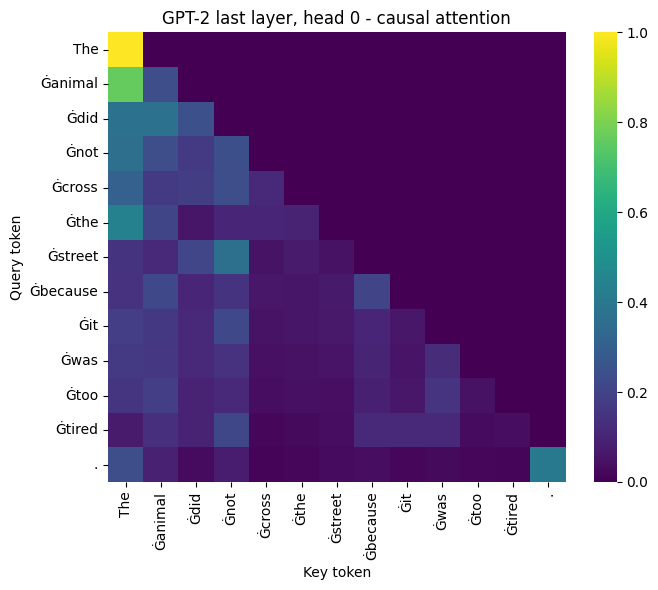

In [24]:
gpt2_tok = AutoTokenizer.from_pretrained("gpt2")
gpt2_model = AutoModelForCausalLM.from_pretrained("gpt2", attn_implementation="eager")
gpt2_model.eval()

g_enc = gpt2_tok("The animal did not cross the street because it was too tired.", return_tensors="pt")
with torch.no_grad():
    g_out = gpt2_model(**g_enc, output_attentions=True)

g_attn = g_out.attentions[-1][0, 0].numpy()        # last layer, head 0
g_tokens = gpt2_tok.convert_ids_to_tokens(g_enc["input_ids"][0])

print("max above diagonal:", np.triu(g_attn, k=1).max())
print("all (almost) zero :", np.triu(g_attn, k=1).max() < 1e-6)

plt.figure(figsize=(7, 6))
sns.heatmap(g_attn, xticklabels=g_tokens, yticklabels=g_tokens, cmap="viridis")
plt.title("GPT-2 last layer, head 0 - causal attention")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/gpt2_causal_attention.png", dpi=120)
plt.show()

The GPT-2 picture is lower-triangular, while the DistilBERT picture in 4.5 is full. So the real decoder uses the same causal mask as my NumPy version.

### 4.8 Padding mask vs causal mask

In [25]:
pad_batch = tok(["I love it.", "This movie was long but I enjoyed every single minute of it."],
                padding=True, return_tensors="pt")

with torch.no_grad():
    pad_out = bert_model(**pad_batch, output_attentions=True)

pad_positions = (pad_batch["attention_mask"][0] == 0).nonzero().flatten()
print("padding positions in sentence 1:", pad_positions.tolist())

att_last = pad_out.attentions[-1][0]               # (12, T, T) for sentence 1
received = att_last[:, :, pad_positions]           # attention going TO the padding
print("max attention received by padding:", received.max().item())

padding positions in sentence 1: [6, 7, 8, 9, 10, 11, 12, 13, 14]
max attention received by padding: 0.0


| | Padding mask | Causal mask |
| --- | --- | --- |
| Purpose | Ignore the fake padding tokens | Stop a token from seeing future tokens |
| Shape pattern | Whole columns of padding positions are masked | Upper triangle is masked |
| Used by | All models that batch sentences (BERT, GPT-2, T5) | Decoders (GPT-2, T5 decoder) |

# Task 5: Cross-Attention, Decoder & Inference
**Objective:** Understand the decoder, cross-attention and how text is generated token by token.
**Expected output:** Translation and summary, cross-attention heatmap, manual greedy loop, decoding table, KV-cache timing.

### 5.1 Decoder architecture
The original Transformer decoder block is:
masked multi-head self-attention -> add & norm -> **cross-attention** over the encoder output -> add & norm -> feed-forward -> add & norm. After the last block, a linear layer and softmax over the vocabulary give the next-token probabilities.

Three families:
- **Encoder-only** (BERT / DistilBERT): bidirectional, good for understanding text.
- **Decoder-only** (GPT-2): drops cross-attention, uses causal self-attention, generates text.
- **Encoder-decoder** (T5): keeps both, good for translation and summarisation.

### 5.2 Cross-attention
In cross-attention the **Queries come from the decoder**, while the **Keys and Values come from the encoder output**. This lets the decoder look at the source sentence while writing the target sentence. It is the same idea as Luong attention in Task 2.4 (decoder state looks at encoder states), but done with Q, K, V projections inside a Transformer.

### 5.3 Run an encoder-decoder model (t5-small)

In [26]:
t5_tok = AutoTokenizer.from_pretrained("t5-small")
t5_model = T5ForConditionalGeneration.from_pretrained("t5-small", attn_implementation="eager")
t5_model.eval()


def t5_generate(prefix, text, **kwargs):
    # prefix tells T5 which task to do, e.g. "translate English to French: "
    ids = t5_tok(prefix + text, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        out = t5_model.generate(**ids, **kwargs)
    return t5_tok.decode(out[0], skip_special_tokens=True)


def translate_fr(text):
    return t5_generate("translate English to French: ", text, max_new_tokens=100)


def summarize(text, max_length=60, min_length=20):
    return t5_generate("summarize: ", text, max_length=max_length, min_length=min_length,
                       num_beams=4, early_stopping=True)


en_sentences = [
    "The house is small.",
    "I would like a cup of coffee, please.",
    "Machine learning is changing the world.",
]
for s in en_sentences:
    print(s, "->", translate_fr(s))

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 675.77it/s]


The house is small. -> La maison est petite.
I would like a cup of coffee, please. -> Je voudrais une tasse de café, je vous prie.
Machine learning is changing the world. -> L'apprentissage en machine change le monde.


In [27]:
# Replace this paragraph with a real news article of 150-300 words if you like
paragraph = (
    "Electric vehicles have moved from a niche product to a mainstream choice in many countries. "
    "Sales have grown quickly over the last few years as battery prices fell and charging networks "
    "expanded. Governments have supported the shift with subsidies and stricter emission rules, "
    "while car makers have announced dozens of new electric models. Still, buyers worry about the "
    "high upfront price, the time needed to charge and the lack of public chargers in smaller towns. "
    "Experts say that cheaper batteries and faster chargers will be the key to the next wave of "
    "growth. Meanwhile, power companies are preparing their grids for the extra demand that millions "
    "of vehicles will place on them, and some are testing systems that let cars send electricity "
    "back to the grid during peak hours. Analysts expect that within a decade electric cars could "
    "make up the majority of new car sales in several large markets, although the pace will differ "
    "from country to country depending on prices, policy and infrastructure."
)

summary = summarize(paragraph, max_length=60, min_length=20)
print("Summary:", summary)
print("Input length  (words):", len(paragraph.split()))
print("Summary length (words):", len(summary.split()))

Summary: electric vehicles have moved from niche product to mainstream choice in many countries. sales have grown quickly over the last few years as battery prices fell and charging networks expanded. experts say cheaper batteries and faster chargers will be key to next wave of growth.
Input length  (words): 165
Summary length (words): 45


### 5.4 Extract and plot cross-attention

cross-attention shape (heads, tgt, src): (8, 6, 11)


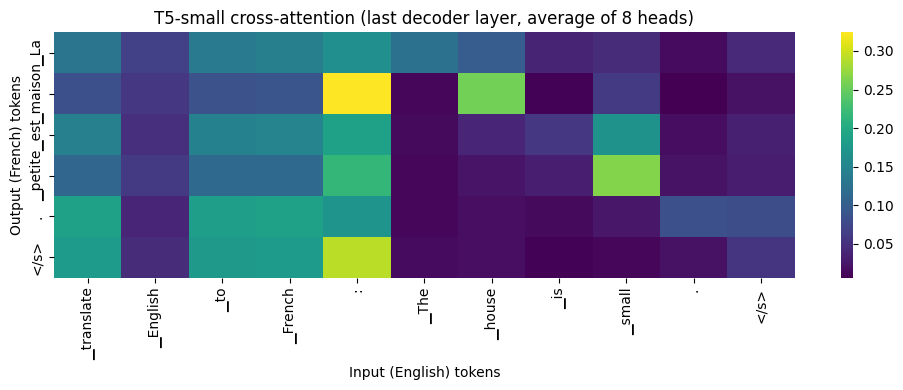

In [28]:
src_text = "translate English to French: The house is small."
tgt_text = "La maison est petite."

src_ids = t5_tok(src_text, return_tensors="pt").input_ids
labels = t5_tok(tgt_text, return_tensors="pt").input_ids

with torch.no_grad():
    t5_out = t5_model(input_ids=src_ids, labels=labels, output_attentions=True)

cross = t5_out.cross_attentions[-1][0]              # last decoder layer: (8, tgt, src)
print("cross-attention shape (heads, tgt, src):", tuple(cross.shape))
cross_avg = cross.mean(dim=0).numpy()               # average over 8 heads

src_tokens = t5_tok.convert_ids_to_tokens(src_ids[0])
tgt_tokens = t5_tok.convert_ids_to_tokens(labels[0])

plt.figure(figsize=(10, 4))
sns.heatmap(cross_avg, xticklabels=src_tokens, yticklabels=tgt_tokens, cmap="viridis")
plt.title("T5-small cross-attention (last decoder layer, average of 8 heads)")
plt.xlabel("Input (English) tokens")
plt.ylabel("Output (French) tokens")
plt.tight_layout()
plt.savefig("plots/cross_attention.png", dpi=120)
plt.show()

**Alignment discussion** (edit after looking at your heatmap): check which English token each French token attends to most, for example whether `maison` looks at `house` and `petite` at `small`. Averaging over heads can blur the picture, and the last layer is not always the cleanest alignment, so only part of the pattern may look sensible.

### 5.5 Inference is autoregressive - manual greedy loop

In [29]:
prompt = "Artificial intelligence will"
input_ids = gpt2_tok(prompt, return_tensors="pt").input_ids

# my own greedy loop
ids = input_ids.clone()
with torch.no_grad():
    for step in range(20):
        logits = gpt2_model(ids).logits[:, -1, :]        # scores for the next token
        next_id = logits.argmax(dim=-1, keepdim=True)    # greedy: pick the best
        ids = torch.cat([ids, next_id], dim=1)           # feed it back in

print("manual :", gpt2_tok.decode(ids[0]))

# library version
with torch.no_grad():
    gen_ids = gpt2_model.generate(input_ids, max_new_tokens=20, do_sample=False,
                                  pad_token_id=gpt2_tok.eos_token_id)
print("generate:", gpt2_tok.decode(gen_ids[0]))
print("identical:", torch.equal(ids, gen_ids))

manual : Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
generate: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
identical: True


A decoder generates **one token at a time**: it predicts the next token, appends it to the input, and runs again. Greedy decoding always takes the highest-scoring token, so the manual loop and `generate()` give the same text.

### 5.6 Decoding strategies

In [30]:
pd.set_option("display.max_colwidth", None)


def generate_text(prompt, seed=None, **kwargs):
    ids = gpt2_tok(prompt, return_tensors="pt")
    if seed is not None:
        torch.manual_seed(seed)
    with torch.no_grad():
        out = gpt2_model.generate(**ids, max_new_tokens=40,
                                  pad_token_id=gpt2_tok.eos_token_id, **kwargs)
    return gpt2_tok.decode(out[0], skip_special_tokens=True)


results = []
results.append(("(a) greedy", generate_text(prompt, do_sample=False)))
results.append(("(b) beam search (5)", generate_text(prompt, do_sample=False,
                                                       num_beams=5, early_stopping=True)))
for seed in [1, 2]:
    results.append((f"(c) temp 0.7, seed {seed}",
                    generate_text(prompt, seed=seed, do_sample=True, temperature=0.7, top_k=0)))
for seed in [1, 2]:
    results.append((f"(d) temp 1.5, seed {seed}",
                    generate_text(prompt, seed=seed, do_sample=True, temperature=1.5, top_k=0)))
results.append(("(e) top_k=50, top_p=0.9", generate_text(prompt, seed=1, do_sample=True,
                                                          top_k=50, top_p=0.9)))

pd.DataFrame(results, columns=["strategy", "output"])

,strategy,output
0,(a) greedy,"Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.\n\n""We're going to be able to"
1,(b) beam search (5),"Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there.\n\n""I think it's going to take a lot of work to get there,"" he said"
2,"(c) temp 0.7, seed 1","Artificial intelligence will help us shape the future of the world.\n\nI am really excited about the future of AI. It is already possible to solve problems of intelligence, computation, and communication and it is also possible"
3,"(c) temp 0.7, seed 2",Artificial intelligence will not be able to solve problems that have never been solved.\n\nThe researchers note that the story of the self-driving car is like a tale of two halves: one is a self-driving
4,"(d) temp 1.5, seed 1","Artificial intelligence will upset inertia in difficult news ones. Countries humans would respect assimil c about every trial, scaven- Detection organizations from the above won % of dislressed orally Fastaturation rofter going judge sentenced k move Tid"
5,"(d) temp 1.5, seed 2",Artificial intelligence will not similarly distress down that angry increase paradigm and presume elsear characterShell pervasive strandsUpon childinitiality gradient spweet votingIn acid GUI libraries pigples are choosing SpecificesKennlaus communities values inputnow
6,"(e) top_k=50, top_p=0.9","Artificial intelligence will help with our search, and perhaps even help us decide which products to buy and which ones not to buy at the moment. I suspect this technology will have its future in the form of advertising, or"


- **Temperature** rescales the scores: low (0.7) makes the model more confident and less random, high (1.5) flattens the probabilities so the text becomes more random and sometimes nonsense.
- **Top-k** keeps only the k most likely tokens; **top-p** keeps the smallest set of tokens whose probabilities add up to p. Both cut off the unlikely tail.
- **Greedy and beam search** are deterministic and can become repetitive; sampling gives variety (different seeds give different text).

### 5.7 KV-cache speed-up

In [31]:
ids = gpt2_tok(prompt, return_tensors="pt")


def time_generate(use_cache, runs=3):
    times = []
    for _ in range(runs):
        start = time.time()
        with torch.no_grad():
            gpt2_model.generate(**ids, max_new_tokens=100, min_new_tokens=100,
                                do_sample=False, use_cache=use_cache,
                                pad_token_id=gpt2_tok.eos_token_id)
        times.append(time.time() - start)
    return float(np.mean(times))


t_cache = time_generate(True)
t_nocache = time_generate(False)
print(f"use_cache=True : {t_cache:.2f} s")
print(f"use_cache=False: {t_nocache:.2f} s")
print(f"speed-up       : {t_nocache / t_cache:.1f}x")

use_cache=True : 3.10 s
use_cache=False: 7.65 s
speed-up       : 2.5x


The key and value vectors of earlier tokens do not change, so they can be **cached** instead of recomputed at every step. With the cache, each new token only needs its own Q, K, V. This is the main speed trick in Transformer inference.

### 5.8 Inference summary table

| | DistilBERT | GPT-2 | T5-small |
| --- | --- | --- | --- |
| Family | Encoder-only | Decoder-only | Encoder-decoder |
| Attention types | Bidirectional self-attention | Causal (masked) self-attention | Self-attention + causal self-attention + cross-attention |
| Can generate text? | No | Yes | Yes |
| Position scheme | Learned (512) | Learned | Relative position bias |
| Typical tasks | Classification, fill-mask | Text generation | Translation, summarisation |
| Example here | Sentiment, fill-mask | Greedy loop, decoding strategies | English to French, summary |

# Task 6: Mini Application, Evaluation & Disadvantages in Practice
**Objective:** Evaluate a pretrained model, measure two disadvantages, and build a small text toolkit.
**Expected output:** Metrics, truncation plot, time-vs-length plot, hallucination check, `text_toolkit()` table, reflection.

### 6.1 Evaluate the pretrained sentiment model on 200 IMDB reviews

Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 310743.97 examples/s]


reviews: 200 | positives: 96
Accuracy 0.870 | Precision 0.889 | Recall 0.833 | F1 0.860 | time 6.4s


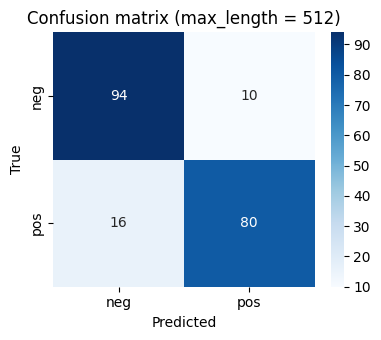

In [34]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb", split="test").shuffle(seed=42).select(range(200))
texts = list(ds["text"])
y_true = np.array(ds["label"])
print("reviews:", len(texts), "| positives:", int(y_true.sum()))


def evaluate(max_length):
    start = time.time()
    res = clf(texts, batch_size=16, truncation=True, max_length=max_length)
    elapsed = time.time() - start
    y_pred = np.array([1 if r["label"] == "POSITIVE" else 0 for r in res])
    return y_pred, elapsed


def metrics(y_true, y_pred):
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) else 0
    rec = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    cm = np.array([[tn, fp], [fn, tp]])
    return acc, prec, rec, f1, cm


y_pred_512, t512 = evaluate(512)
acc, prec, rec, f1, cm = metrics(y_true, y_pred_512)
print(f"Accuracy {acc:.3f} | Precision {prec:.3f} | Recall {rec:.3f} | F1 {f1:.3f} | time {t512:.1f}s")

plt.figure(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
plt.title("Confusion matrix (max_length = 512)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig("plots/confusion_matrix.png", dpi=120)
plt.show()

### 6.2 Effect of truncation length

max_length  64: accuracy 0.750, time 0.9s
max_length 128: accuracy 0.775, time 1.3s
max_length 256: accuracy 0.840, time 2.6s
max_length 512: accuracy 0.870, time 5.3s


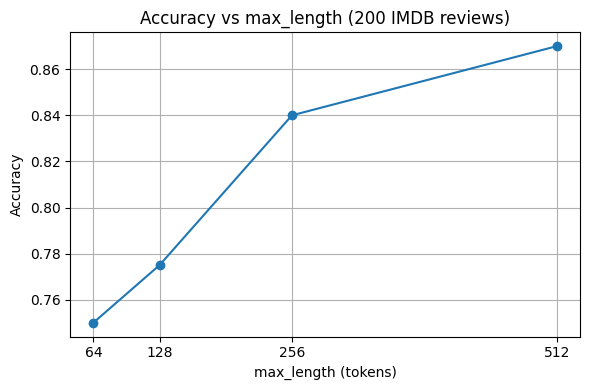

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Reviews longer than 512 tokens: 18 out of 200


In [35]:
lengths = [64, 128, 256, 512]
accs, times = [], []
for L in lengths:
    pred, t = evaluate(L)
    a = metrics(y_true, pred)[0]
    accs.append(a)
    times.append(t)
    print(f"max_length {L:3d}: accuracy {a:.3f}, time {t:.1f}s")

plt.figure(figsize=(6, 4))
plt.plot(lengths, accs, marker="o")
plt.title("Accuracy vs max_length (200 IMDB reviews)")
plt.xlabel("max_length (tokens)")
plt.ylabel("Accuracy")
plt.xticks(lengths)
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/truncation_accuracy.png", dpi=120)
plt.show()

token_counts = [len(x) for x in tok(texts, truncation=False)["input_ids"]]
over = int(np.sum(np.array(token_counts) > 512))
print("Reviews longer than 512 tokens:", over, "out of", len(texts))

### 6.3 Cost grows with sequence length

length  32: 30.6 ms
length  64: 38.7 ms
length 128: 73.5 ms
length 256: 120.1 ms
length 512: 230.0 ms


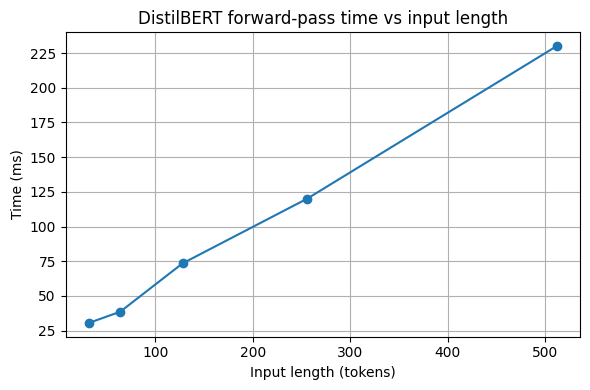

time(512) / time(32) = 7.5 (length grew 16x)


In [36]:
long_text = "This movie was great and I really loved the acting and the story. " * 100

model.eval()
lens = [32, 64, 128, 256, 512]
avg_times = []

for L in lens:
    enc_L = tok(long_text, truncation=True, max_length=L, return_tensors="pt")
    assert enc_L["input_ids"].shape[1] == L
    with torch.no_grad():
        model(**enc_L)                       # warm-up run
        runs = []
        for _ in range(10):
            start = time.time()
            model(**enc_L)
            runs.append(time.time() - start)
    avg_times.append(np.mean(runs))
    print(f"length {L:3d}: {avg_times[-1] * 1000:.1f} ms")

plt.figure(figsize=(6, 4))
plt.plot(lens, np.array(avg_times) * 1000, marker="o")
plt.title("DistilBERT forward-pass time vs input length")
plt.xlabel("Input length (tokens)")
plt.ylabel("Time (ms)")
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/time_vs_length.png", dpi=120)
plt.show()

print("time(512) / time(32) =", round(avg_times[-1] / avg_times[0], 1), "(length grew 16x)")

Attention compares every token with every other token, so its cost grows roughly with the **square** of the length (doubling the length means about 4x the attention work). This is one reason models have a context limit such as 512 tokens. Honest note: on a CPU at small sizes the feed-forward layers also matter and the curve can look closer to linear, so I only expect the quadratic growth to show clearly at larger lengths. (Edit based on your own plot.)

### 6.4 Hallucination check

In [37]:
fact_prompts = [
    "The capital of Australia is",
    "The author of the novel Pride and Prejudice is",
    "The inventor of the telephone was",
]

for p in fact_prompts:
    ids_f = gpt2_tok(p, return_tensors="pt")
    with torch.no_grad():
        o = gpt2_model.generate(**ids_f, max_new_tokens=30, do_sample=False,
                                pad_token_id=gpt2_tok.eos_token_id)
    print(gpt2_tok.decode(o[0], skip_special_tokens=True))
    print("-" * 60)

The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station.

The coal industry is also the world's largest
------------------------------------------------------------
The author of the novel Pride and Prejudice is a former member of the National Security Council.

The author of the novel is a former member of the National Security Council.

The author
------------------------------------------------------------
The inventor of the telephone was a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who
------------------------------------------------------------


In [38]:
# Read the three outputs above and fill in your own grade:
# "correct", "partly correct" or "wrong"
grades = ["FILL ME", "FILL ME", "FILL ME"]

pd.DataFrame({"prompt": fact_prompts, "my grade": grades})

,prompt,my grade
0,The capital of Australia is,FILL ME
1,The author of the novel Pride and Prejudice is,FILL ME
2,The inventor of the telephone was,FILL ME


### 6.5 Build the mini application

In [39]:
MAX_WORDS = 1000          # inputs longer than this are cut


def text_toolkit(text):
    # handle bad input
    if not isinstance(text, str) or text.strip() == "":
        return {"sentiment": None, "score": None, "summary": None, "french": None,
                "message": "Empty or invalid input - please give some text."}

    message = "ok"
    words = text.split()
    if len(words) > MAX_WORDS:
        text = " ".join(words[:MAX_WORDS])
        message = f"Input was very long, only the first {MAX_WORDS} words were used."
    elif len(words) < 5:
        message = "Input is very short, the summary may not be meaningful."

    # (a) sentiment
    r = clf(text, truncation=True, max_length=512)[0]

    # (b) summary (max_length = 60)
    summ = summarize(text, max_length=60, min_length=5)

    # (c) French translation of the summary
    fr = translate_fr(summ)

    return {"sentiment": r["label"], "score": round(r["score"], 3),
            "summary": summ, "french": fr, "message": message}


passages = {
    "review": ("I went to see this film with low expectations, but it completely won me over. "
               "The acting was warm and natural, the story kept surprising me, and the music "
               "matched every scene. A few jokes fell flat in the middle, but the ending was "
               "emotional and satisfying. I would happily watch it again."),
    "news": paragraph,
    "own": ("Our college organised a two-day technical fest last week. Students from many "
            "departments built small projects, and the robotics and web design events were the "
            "most popular. The teachers helped with judging, and the winners received prizes "
            "from the principal on the final evening."),
}

rows = []
for name, passage in passages.items():
    res = text_toolkit(passage)
    res["passage"] = name
    rows.append(res)

toolkit_df = pd.DataFrame(rows)[["passage", "sentiment", "score", "summary", "french", "message"]]
toolkit_df

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,passage,sentiment,score,summary,french,message
0,review,POSITIVE,1.000,"the acting was warm and natural, the story kept surprising me. the ending was emotional and satisfying.","l'acteur était chaleureux et naturel, l'histoire me surprisait, la fin était émotionnelle et satisfaisante.",ok
1,news,NEGATIVE,0.727,electric vehicles have moved from niche product to mainstream choice in many countries. sales have grown quickly over the last few years as battery prices fell and charging networks expanded. experts say cheaper batteries and faster chargers will be key to next wave of growth.,"Les véhicules électriques sont passés de la niche à la sélection en général dans de nombreux pays. Les ventes ont augmenté rapidement au cours des dernières années, à mesure que les prix des piles ont baissé et que les réseaux de chargement se sont élargis. Les experts pensent que les batteries moins coûteuses et les chargeurs plus rapides seront essentiels à la prochaine vague de",ok
2,own,POSITIVE,0.999,our college organised a two-day technical fest last week. students from many departments built small projects. the teachers helped with judging.,Notre collège a organisé une fête technique de deux jours la semaine dernière. les étudiants de nombreux départements ont construit de petits projets. les enseignants ont aidé à juger.,ok


In [40]:
# bad inputs
print(text_toolkit(""))
print(text_toolkit("   "))
print(text_toolkit(None))
print(text_toolkit("great movie " * 3000)["message"])      # very long input

{'sentiment': None, 'score': None, 'summary': None, 'french': None, 'message': 'Empty or invalid input - please give some text.'}
{'sentiment': None, 'score': None, 'summary': None, 'french': None, 'message': 'Empty or invalid input - please give some text.'}
{'sentiment': None, 'score': None, 'summary': None, 'french': None, 'message': 'Empty or invalid input - please give some text.'}
Input was very long, only the first 1000 words were used.


### 6.6 What I learned about Transformers
*(Write this in your own words after running the notebook. Use the prompts below.)*

**(a) What I understand best / what is still unclear:**
I understand ___ best because ___. One thing that is still unclear is ___.

**(b) Theory vs real model:**
It matched the theory that ___ (for example my attention matrix matched DistilBERT, max difference ___). One thing that surprised me was ___.

**(c) Two disadvantages I measured:**
1. Cost grows with length: the forward pass took ___ ms at 32 tokens and ___ ms at 512 tokens.
2. Limited context / hallucination: ___ of 200 reviews were longer than 512 tokens, and GPT-2 got ___ of 3 facts right.

**(d) A real application I would build:**
I would build ___ using a ___ (encoder-only / decoder-only / encoder-decoder) model because ___.

### 6.7 Notebook quality - requirements.txt

In [41]:
from importlib.metadata import version

packages = ["transformers", "torch", "datasets", "matplotlib", "seaborn", "numpy", "pandas"]
lines = [f"{p}=={version(p)}" for p in packages]

with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print("\n".join(lines))

transformers==5.20.1
torch==2.11.0+cu128
datasets==5.1.0
matplotlib==3.10.0
seaborn==0.13.2
numpy==2.3.5
pandas==2.3.3
